# Inertia(wcss)

In [ ]:
# create the dataset

from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt

X, y = make_blobs(
    n_samples=300,      # Total data points
    centers=4,          # Number of clusters
    cluster_std=0.7,    # Cluster spread
    random_state=42     # Same output every run
)

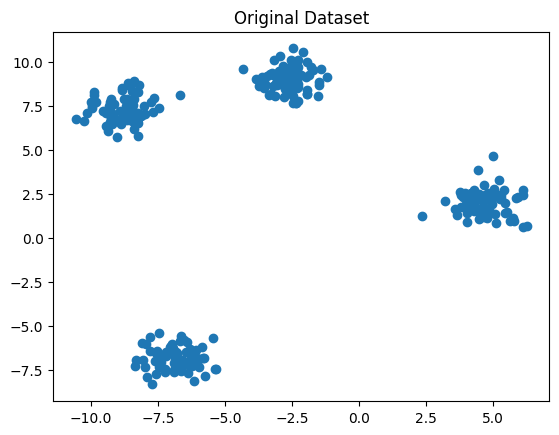

In [ ]:
# visualize dataset
plt.scatter(X[:,0], X[:,1])
plt.title("Original Dataset")
plt.show()

In [ ]:
# apply model
from sklearn.cluster import KMeans
kmeans = KMeans(
    n_clusters=4,
    random_state=42
)

kmeans.fit(X)

KMeans(n_clusters=4, random_state=42)

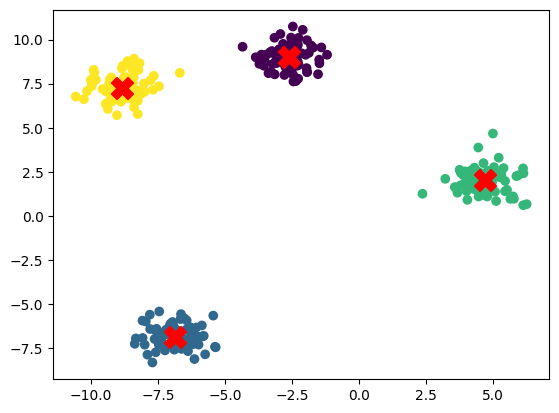

In [ ]:
# Visualization After Clustering
plt.scatter(X[:,0], X[:,1],
            c=kmeans.labels_)

plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    color="red",
    marker="X",
    s=250
)

plt.show()

In [ ]:
# evaluation metric
print("Inertia:", kmeans.inertia_)

Inertia: 277.51796097746086


# Elbow method.

In [ ]:
# import libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

In [ ]:
# create the dataset
x,y = make_blobs(
    n_samples=300,
    centers=6,
    cluster_std=0.8,
    random_state=42
)

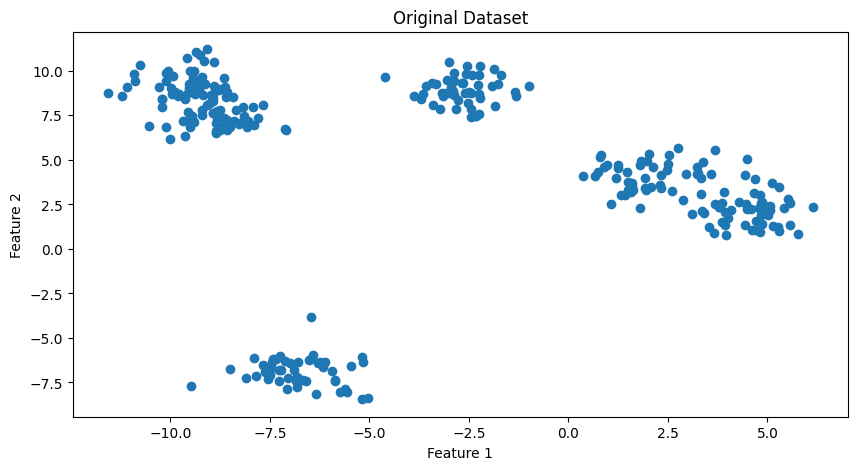

In [ ]:
# visualize  the  dataset
plt.figure(figsize=(10,5))
plt.scatter(x[:,0], x[:,1])
plt.title("Original Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [ ]:
# calculate the wcss
wcss = []
for i in range(1,11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42
    )
    kmeans.fit(x)
    wcss.append(kmeans.inertia_)


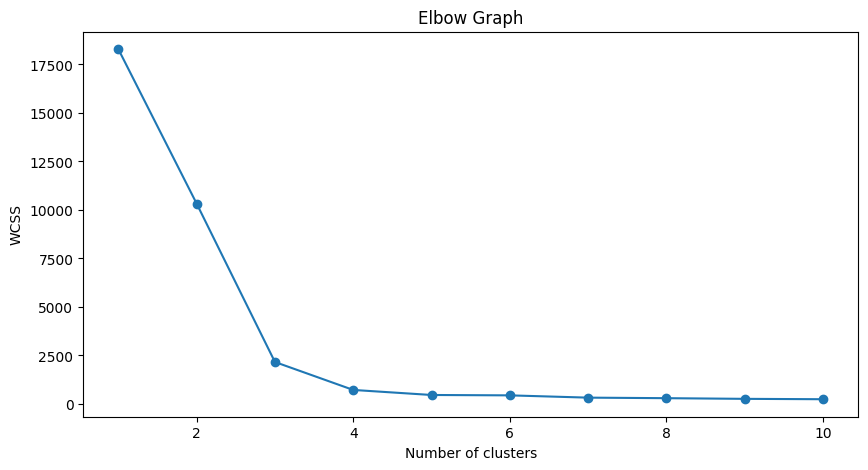

In [ ]:
# elbow graph
plt.figure(figsize=(10,5))
plt.plot(range(1,11), wcss, marker="o")
plt.title("Elbow Graph")
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.show()

In [ ]:
# choose the best k value with model training

best_kmeans = KMeans(
    n_clusters=4,
    random_state=42
)
best_kmeans.fit(x)

# lables
labels = best_kmeans.labels_
# print("find the cluster", lable)

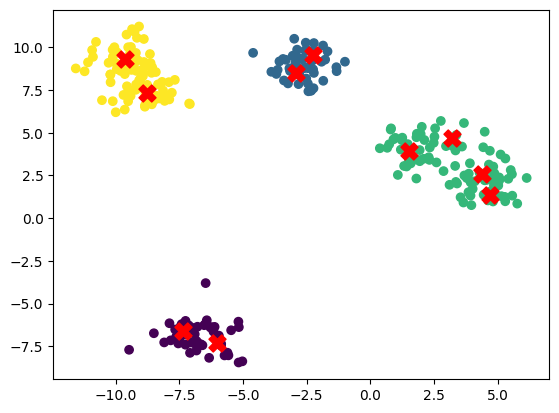

In [ ]:
# final visualization
plt.scatter(x[:,0], x[:,1], c=labels)

plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    color="red",
    marker="X",
    s=150
)

plt.show()

# silhouette score

In [ ]:
# import libraries
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

In [ ]:
# create the same dataset for the compartion of the silhouette score

x, y = make_blobs(
    n_samples=300,
    centers=6,
    cluster_std=0.8,
    random_state=42
)

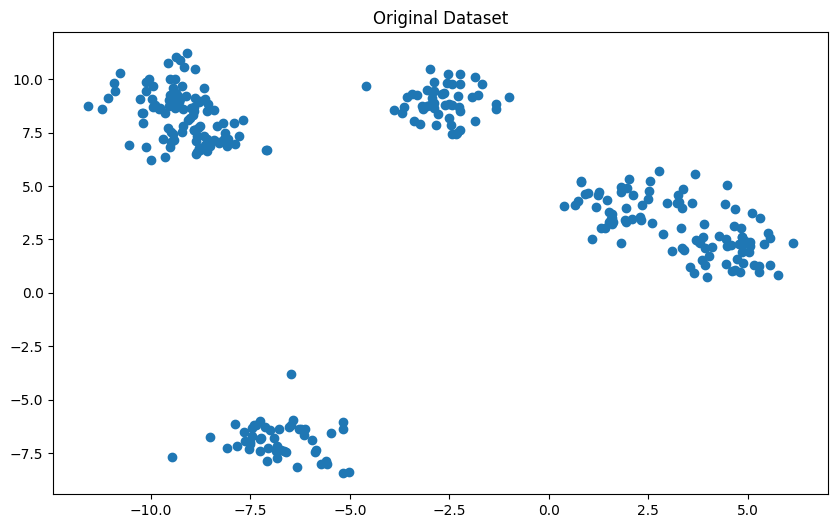

In [ ]:
# visualization dataset
plt.figure(figsize=(10,6))
plt.scatter(x[:,0],x[:,1])
plt.title("Original Dataset")
plt.show()

In [ ]:
from sklearn import cluster
# training final model
kmeans = KMeans(
    random_state=42,
    n_clusters=  4
)
kmeans.fit(x)

KMeans(n_clusters=4, random_state=42)

In [ ]:
# labels
labels = kmeans.labels_

# calculate the silouette score
score = silhouette_score(x, labels)
print("Silhouette Score:", score)


Silhouette Score: 0.7558373634776712


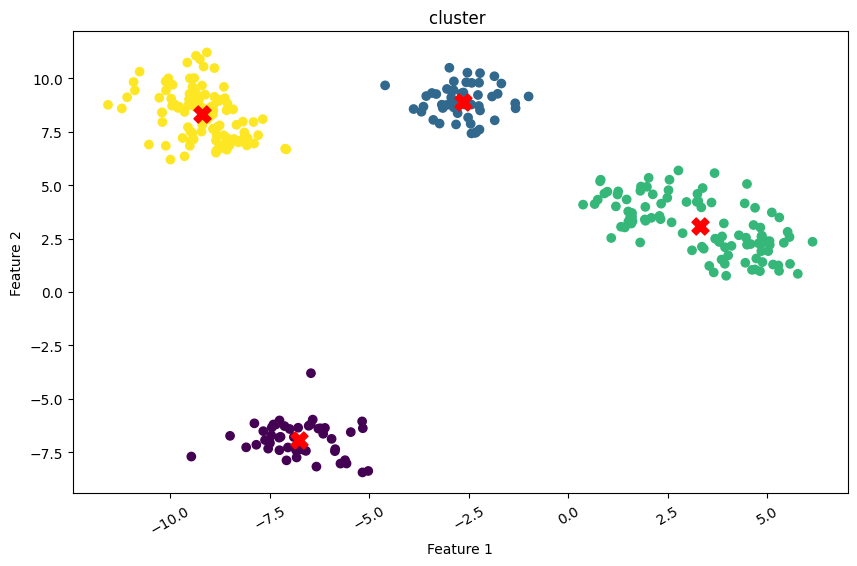

In [ ]:
# visualize the cluster
plt.figure(figsize=(10,6))
plt.scatter(x[:,0], x[:,1], c=labels)
plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    color="red",
    marker="X",
    s=150
)
plt.title("cluster ")
plt.xlabel("Feature 1")
plt.xticks(rotation=30)
plt.ylabel("Feature 2")
plt.show()

# davices-bouldin Index

In [ ]:
# import libraries
from sklearn.datasets import make_blobs
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
from sklearn.metrics import davies_bouldin_score

In [ ]:
# create the dataset
x,y = make_blobs(
    n_samples=500,
    centers=6,
    cluster_std=0.7,
    random_state=42
)

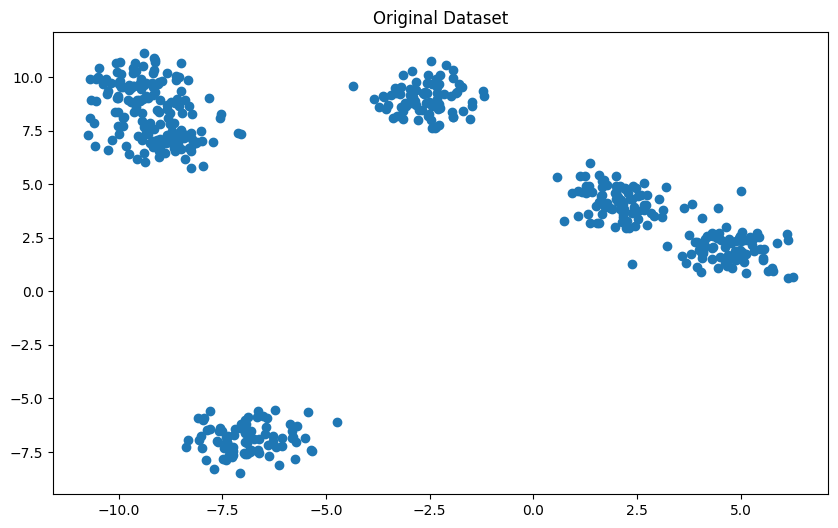

In [ ]:
# visualize dataset
plt.figure(figsize=(10,6))
plt.scatter(x[:,0], x[:,1])
plt.title("Original Dataset")
plt.show()

In [ ]:
# apply DBSCAN
dbscan = DBSCAN(
    eps=1.0,
    min_samples=5
)
labels = dbscan.fit_predict(x)

In [ ]:
print(labels[:10])

[ 0  1  1 -1  1  0  1  1  2  2]


In [ ]:
score = davies_bouldin_score(
    x,
    labels
)

print("Davies-Bouldin Index :", score)

Davies-Bouldin Index : 0.5269682043975472


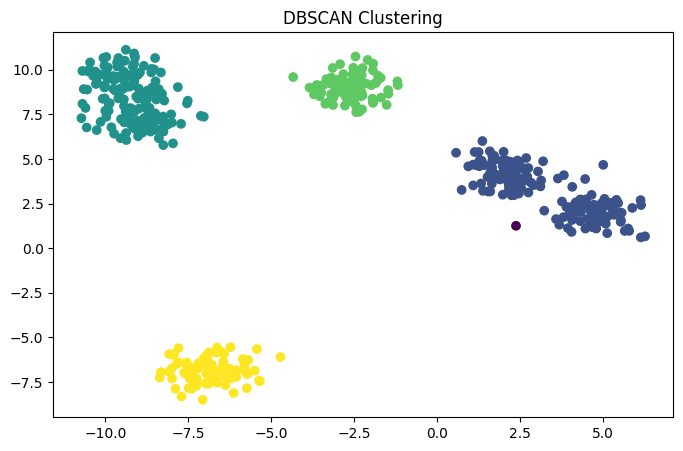

In [ ]:
# Visualize clusters
plt.figure(figsize=(8,5))
plt.scatter(x[:,0], x[:,1], c=labels)
plt.title("DBSCAN Clustering")
plt.show()

# CH(Calinski-Harabasz) score method

In [9]:
# import libraries
from sklearn.datasets import make_blobs
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
import matplotlib.pyplot as plt

In [20]:
# create the dataset
x,y = make_blobs(
    n_samples=500,
    centers=6,
    cluster_std=2.5,
    random_state=4)

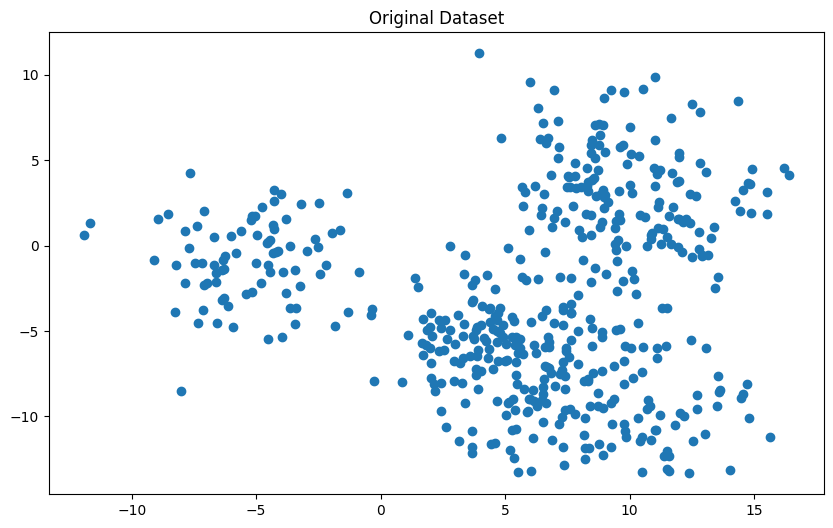

In [21]:
# visualize the datasets
plt.figure(figsize=(10,6))
plt.scatter(x[:,0], x[:,1])
plt.title("Original Dataset")
plt.show()

In [22]:
# apply the gaussianmixture
gmm = GaussianMixture(
    n_components=4,
    random_state=42
)
labels = gmm.fit_predict(x)


In [29]:
# calculate the ch score
score_1 = calinski_harabasz_score(x, labels)
print("Calinski-Harabasz Score:", score_1)

Calinski-Harabasz Score: 735.0529747526241


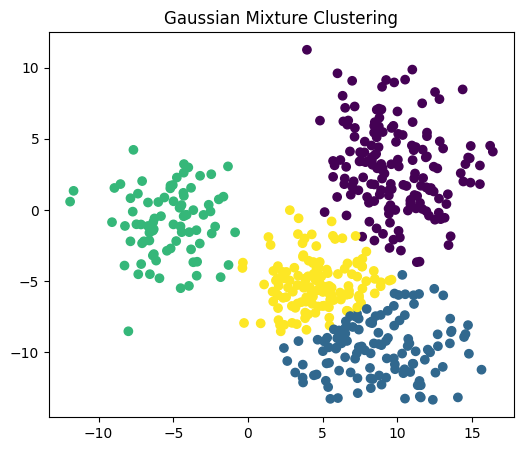

In [24]:
# Visualize Clusters
plt.figure(figsize=(6,5))
plt.scatter(x[:,0], x[:,1], c=labels)
plt.title("Gaussian Mixture Clustering")
plt.show()

In [25]:
# apply the kmeans clutering
kmeans = KMeans(
    n_clusters=4,
    random_state=42
)
kmeans_model_labels = kmeans.fit_predict(x)


In [30]:
# ch score for the kmeans algorthms
score_2 = calinski_harabasz_score(x, kmeans_model_labels)
print("Calinski-Harabasz Score:", score_2)

Calinski-Harabasz Score: 748.2392343214689


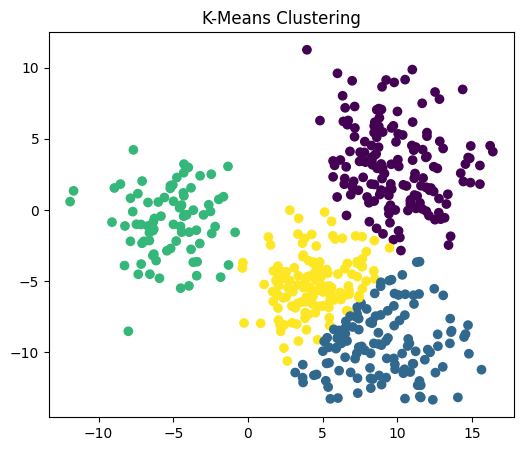

In [27]:
# visualization
plt.figure(figsize=(6,5))
plt.scatter(x[:,0], x[:,1], c=kmeans_model_labels)
plt.title("K-Means Clustering")
plt.show()

In [32]:
# compare the ch score
print("Gaussian Mixture Model CH Score:", score_1)
print("K-Means Model CH Score:", score_2)

Gaussian Mixture Model CH Score: 735.0529747526241
K-Means Model CH Score: 748.2392343214689
